In [3]:
# Chuẩn bị các thư viện cần thiết
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
from PIL import Image

In [4]:
# Xác định thư mục gốc repo (đường dẫn tương đối, chạy được trên mọi máy / Colab)
here = Path.cwd().resolve()
repo_root = next((p for p in [here, *here.parents]
                  if (p / ".git").exists() or (p / "requirements.txt").exists()
                  or (p / "src").is_dir()), here)
sys.path.insert(0, str(repo_root))

from src.config import ROOT, RAW   # dùng chung đường dẫn với phần train
print("ROOT:", ROOT, "\nRAW :", RAW)

train = pd.read_csv(RAW / "Train.csv")
test = pd.read_csv(RAW / "Test.csv")
meta = pd.read_csv(RAW / "Meta.csv")

for name, df in [("train", train), ("test", test), ("meta", meta)]:
    print(name, df.shape)
    print(df.head(4), "\n")

ROOT: C:\Users\MyPC\Desktop\CodeVS\DeepLearning 
RAW : C:\Users\MyPC\Desktop\CodeVS\DeepLearning\data\raw
train (39209, 8)
   Width  Height  Roi.X1  Roi.Y1  Roi.X2  Roi.Y2  ClassId  \
0     27      26       5       5      22      20       20   
1     28      27       5       6      23      22       20   
2     29      26       6       5      24      21       20   
3     28      27       5       6      23      22       20   

                             Path  
0  Train/20/00020_00000_00000.png  
1  Train/20/00020_00000_00001.png  
2  Train/20/00020_00000_00002.png  
3  Train/20/00020_00000_00003.png   

test (12630, 8)
   Width  Height  Roi.X1  Roi.Y1  Roi.X2  Roi.Y2  ClassId            Path
0     53      54       6       5      48      49       16  Test/00000.png
1     42      45       5       5      36      40        1  Test/00001.png
2     48      52       6       6      43      47       38  Test/00002.png
3     27      29       5       5      22      24       33  Test/00003.png 

m

In [5]:
# Chuẩn bị thư mục lưu ảnh
FIG = ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

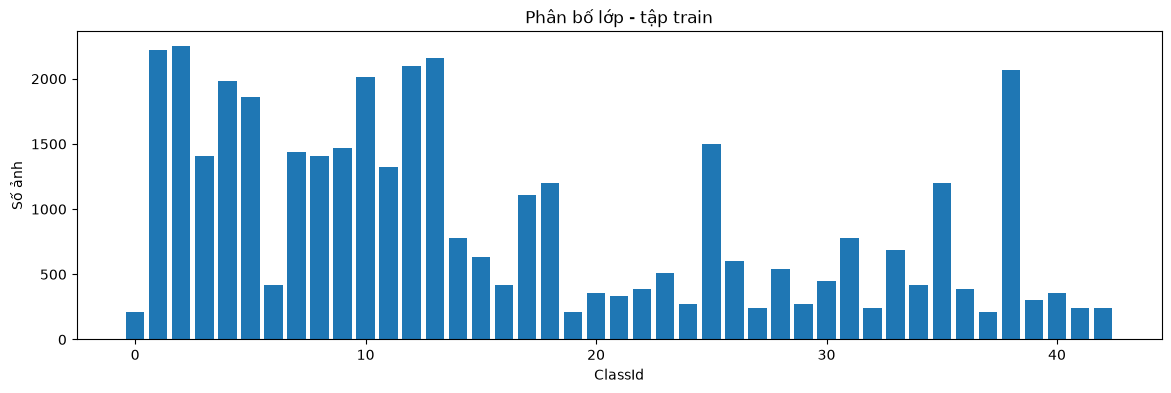

min: 210 | max: 2250 | tỉ lệ max/min: 10.7
ClassId
0     210
37    210
19    210
32    240
27    240
Name: count, dtype: int64
ClassId
38    2070
12    2100
13    2160
1     2220
2     2250
Name: count, dtype: int64


In [6]:
# (1) Phân bố số ảnh theo lớp
counts = train["ClassId"].value_counts().sort_index()
plt.figure(figsize=(14, 4))
plt.bar(counts.index, counts.values)
plt.xlabel("ClassId"); plt.ylabel("Số ảnh"); plt.title("Phân bố lớp - tập train")
plt.savefig(FIG / "class_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

print("min:", counts.min(), "| max:", counts.max(),
      "| tỉ lệ max/min: %.1f" % (counts.max() / counts.min()))
print(counts.sort_values().head(5))
print(counts.sort_values().tail(5))

### 📌 Nhận xét về phân bố dữ liệu tập Train:
- **Hiện tượng mất cân bằng lớp (Class Imbalance):** 
  - Phân bố giữa 43 lớp biển báo không đồng đều, chênh lệch giữa lớp nhiều nhất và ít nhất lên tới gần **10 lần**.
  - Các lớp chiếm đa số (> 2.000 ảnh): `ClassId` 1, 2, 10, 12, 13, 38.
  - Các lớp thiểu số (< 300 ảnh): `ClassId` 0, 19, 24, 27, 32, 37, 41, 42.
- **Rủi ro đối với mô hình:**
  - Mô hình có xu hướng học tốt và dự đoán thiên vị về các lớp phổ biến, trong khi độ chính xác (Recall) ở các lớp hiếm sẽ bị thấp.
  - Đánh giá chỉ bằng chỉ số *Accuracy* thông thường sẽ không phản ánh đúng hiệu quả thực tế.
- **Đề xuất hướng xử lý:**
  - Áp dụng kỹ thuật tăng cường dữ liệu (**Data Augmentation**: xoay, chỉnh sáng, lật, co giãn) tập trung nhiều hơn vào các lớp thiểu số.
  - Sử dụng **Class Weights** trong hàm Loss hoặc thay bằng **Focal Loss** khi huấn luyện.
  - Đánh giá mô hình bằng **Confusion Matrix** thay vì chỉ nhìn vào Accuracy.

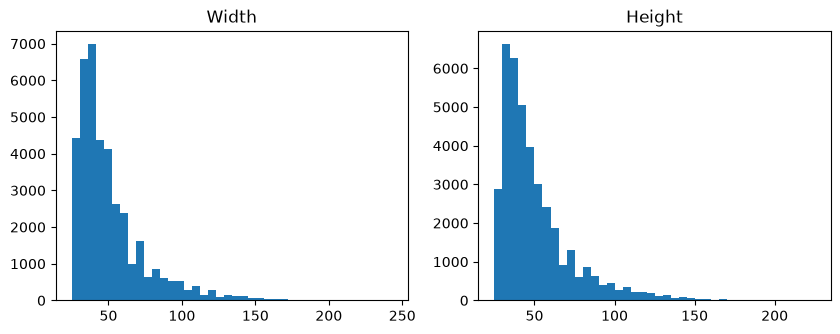

              Width        Height
count  39209.000000  39209.000000
mean      50.835880     50.328930
std       24.306933     23.115423
min       25.000000     25.000000
25%       35.000000     35.000000
50%       43.000000     43.000000
75%       58.000000     58.000000
max      243.000000    225.000000


In [7]:
# (2) Phân bố kích thước ảnh
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(train["Width"], bins=40); ax[0].set_title("Width")
ax[1].hist(train["Height"], bins=40); ax[1].set_title("Height")
plt.savefig(FIG / "size_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

print(train[["Width", "Height"]].describe())

### 📌 Nhận xét về kích thước ảnh (Width & Height):
- **Phân bố kích thước không đồng đều:** 
  - Kích thước ảnh dao động trong khoảng khá rộng: từ rất nhỏ (~25x25 px) cho đến kích thước lớn (>200x200 px).
  - Cả hai biểu đồ chiều rộng (*Width*) và chiều cao (*Height*) đều có **phân phối lệch phải (right-skewed)** rõ rệt.
- **Tập trung chủ yếu ở độ phân giải thấp:**
  - Phần lớn dữ liệu tập trung ở dải kích thước nhỏ, phổ biến từ **30px đến 50px** (đỉnh tập trung quanh mốc ~40px). 
  - Tỉ lệ chiều rộng và chiều cao có dạng phân bố tương đồng nhau, cho thấy hầu hết các ảnh đều có **tỉ lệ khung hình xấp xỉ 1:1 (hình vuông)**, phù hợp với đặc trưng hình học của biển báo (hình tròn, tam giác, hình vuông).
- **Đề xuất bước Tiền xử lý (Preprocessing):**
  - Vì mạng nơ-ron tích chập (CNN) yêu cầu kích thước đầu vào cố định, bắt buộc phải thực hiện **Resize** ảnh về cùng một kích thước chuẩn.
  - Kích thước đầu vào khuyến nghị nên chọn **$48 \times 48$**:
    - *Lý do:* Kích thước này rất gần với độ phân giải thực tế của đa số ảnh gốc (~40px), giúp giữ được nét đặc trưng mà không làm ảnh bị vỡ/nhoè do nội suy phóng đại (upsampling), đồng thời tối ưu hoá tốc độ huấn luyện mô hình.

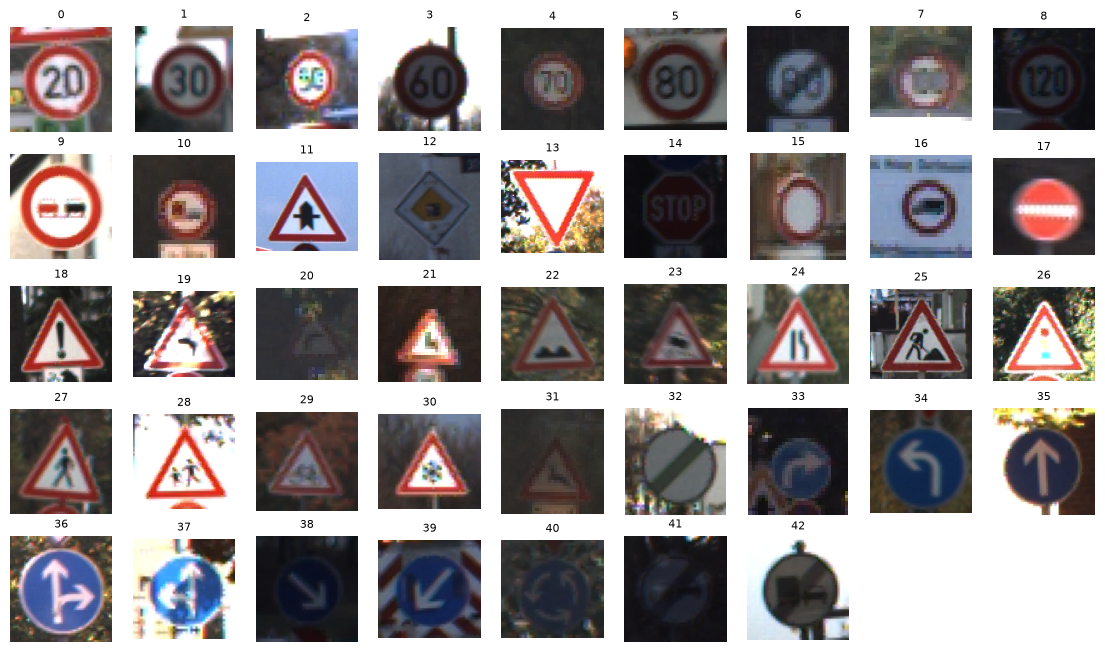

In [8]:
# (3a) Mỗi lớp 1 ảnh mẫu (lưới 43 ảnh)
fig, axes = plt.subplots(5, 9, figsize=(14, 8))
for ax in axes.ravel():
    ax.axis("off")
for c in range(43):
    p = train[train["ClassId"] == c].sample(1, random_state=0)["Path"].iloc[0]
    axes.ravel()[c].imshow(Image.open(RAW / p))
    axes.ravel()[c].set_title(str(c), fontsize=8)
plt.savefig(FIG / "samples_per_class.png", dpi=200, bbox_inches="tight")
plt.show()  

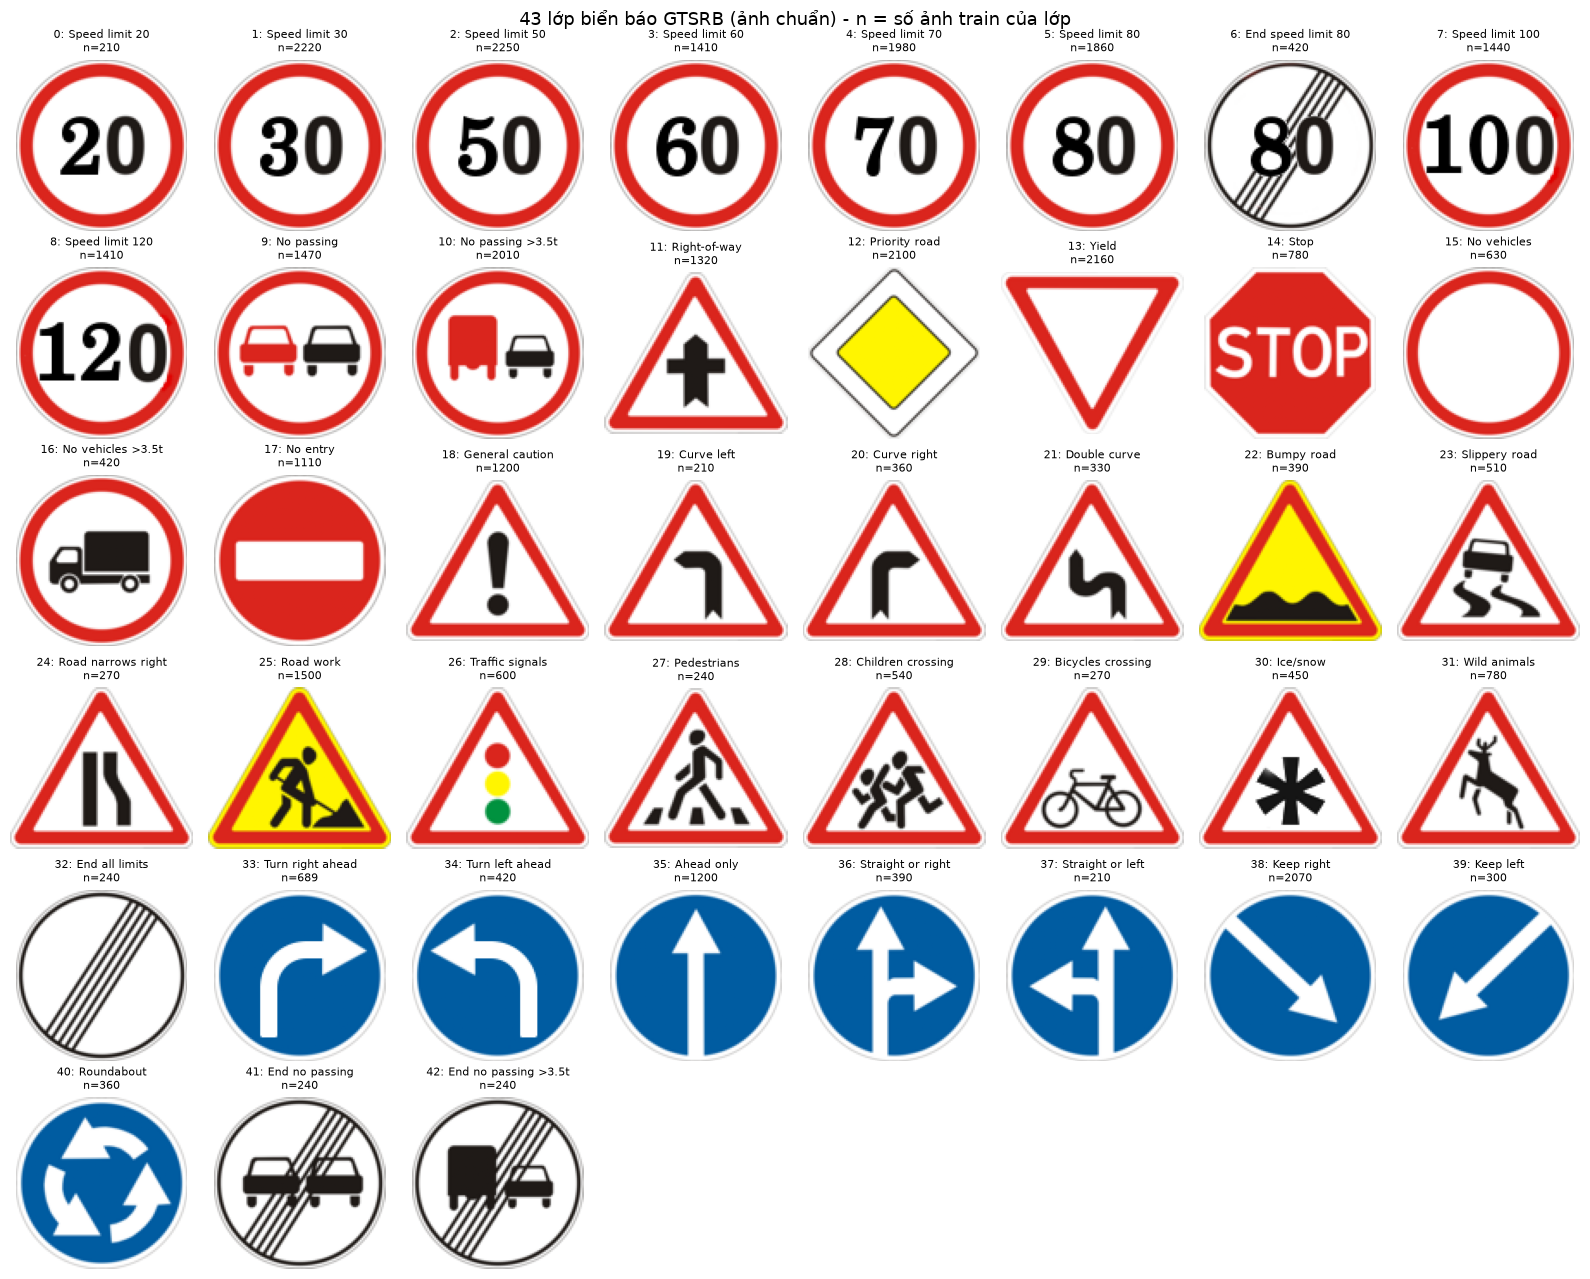

In [15]:
# (3b) Bộ ảnh chuẩn (Meta): 43 biển báo mẫu, mỗi lớp một ảnh
CLASS_NAMES = {
    0: "Speed limit 20", 1: "Speed limit 30", 2: "Speed limit 50", 3: "Speed limit 60",
    4: "Speed limit 70", 5: "Speed limit 80", 6: "End speed limit 80", 7: "Speed limit 100",
    8: "Speed limit 120", 9: "No passing", 10: "No passing >3.5t",
    11: "Right-of-way", 12: "Priority road", 13: "Yield", 14: "Stop",
    15: "No vehicles", 16: "No vehicles >3.5t", 17: "No entry", 18: "General caution",
    19: "Curve left", 20: "Curve right", 21: "Double curve", 22: "Bumpy road",
    23: "Slippery road", 24: "Road narrows right", 25: "Road work", 26: "Traffic signals",
    27: "Pedestrians", 28: "Children crossing", 29: "Bicycles crossing", 30: "Ice/snow",
    31: "Wild animals", 32: "End all limits", 33: "Turn right ahead", 34: "Turn left ahead",
    35: "Ahead only", 36: "Straight or right", 37: "Straight or left", 38: "Keep right",
    39: "Keep left", 40: "Roundabout", 41: "End no passing", 42: "End no passing >3.5t",
}

n_per_class = train["ClassId"].value_counts()
meta_sorted = meta.sort_values("ClassId").reset_index(drop=True)

fig, axes = plt.subplots(6, 8, figsize=(16, 13))
for ax in axes.ravel():
    ax.axis("off")

for ax, (_, row) in zip(axes.ravel(), meta_sorted.iterrows()):
    cid = int(row["ClassId"])
    ax.imshow(Image.open(RAW / row["Path"]))
    ax.set_title(f"{cid}: {CLASS_NAMES[cid]}\nn={n_per_class.get(cid, 0)}", fontsize=8)

plt.suptitle("43 lớp biển báo GTSRB (ảnh chuẩn) - n = số ảnh train của lớp", fontsize=13)
plt.tight_layout()
plt.savefig(FIG / "meta_43_classes.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
# (3c) Hình dạng biển báo (từ Meta)
shape_dict = {0: "Triangle", 1: "Circle", 2: "Diamond", 3: "Hexagon", 4: "Inverse Triangle"}
meta["ShapeName"] = meta["ShapeId"].map(shape_dict)

print(meta.groupby(["ShapeId", "ShapeName"]).agg(
    so_lop=("ClassId", "count"),
    cac_lop=("ClassId", lambda s: sorted(s.tolist())),
))

                          so_lop  \
ShapeId ShapeName                  
0       Triangle              15   
1       Circle                25   
2       Diamond                1   
3       Hexagon                1   
4       Inverse Triangle       1   

                                                                    cac_lop  
ShapeId ShapeName                                                            
0       Triangle          [11, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 2...  
1       Circle            [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 15, 16, 17,...  
2       Diamond                                                        [12]  
3       Hexagon                                                        [14]  
4       Inverse Triangle                                               [13]  


In [18]:
# (4) Thống kê ảnh chất lượng thấp: nhỏ, tối, lệch tâm
small = train[(train["Width"] < 30) | (train["Height"] < 30)]
print("ảnh <30px:", len(small), "(%.1f%%)" % (100 * len(small) / len(train)))

ảnh <30px: 3740 (9.5%)


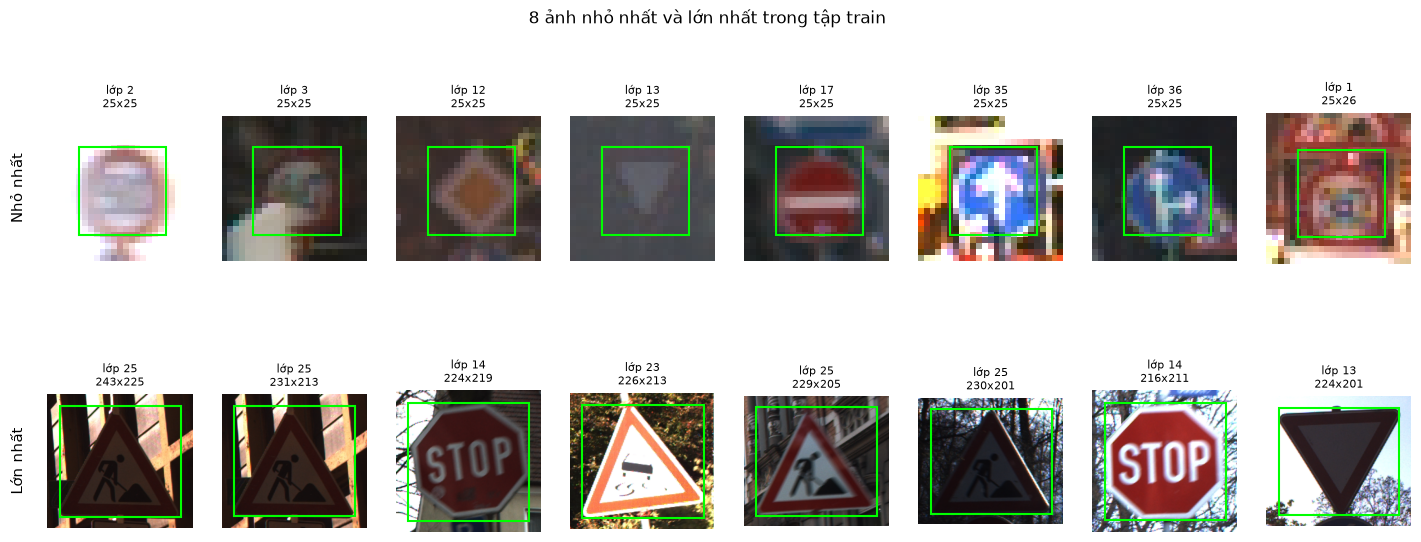

In [19]:
# (5) So sánh 8 ảnh nhỏ nhất và 8 ảnh lớn nhất (theo diện tích), kèm khung ROI
def draw_row(axes, df, draw_roi=True):
    """Vẽ mỗi dòng của df lên một ô trong axes, kèm khung ROI."""
    for ax, (_, r) in zip(axes, df.iterrows()):
        ax.imshow(Image.open(RAW / r["Path"]))
        if draw_roi:
            ax.add_patch(patches.Rectangle(
                (r["Roi.X1"], r["Roi.Y1"]),
                r["Roi.X2"] - r["Roi.X1"], r["Roi.Y2"] - r["Roi.Y1"],
                fill=False, edgecolor="lime", linewidth=1.5))
        ax.set_title(f"lớp {r['ClassId']}\n{r['Width']}x{r['Height']}", fontsize=8)
        ax.axis("off")


def compare_extremes(df, n=8, fname=None):
    """Hàng trên: n ảnh nhỏ nhất, hàng dưới: n ảnh lớn nhất (theo diện tích)."""
    df = df.assign(area=df["Width"] * df["Height"])
    rows = [("Nhỏ nhất", df.nsmallest(n, "area")),
            ("Lớn nhất", df.nlargest(n, "area"))]

    fig, axes = plt.subplots(2, n, figsize=(2.2 * n, 6.5))
    for row_axes, (label, sub) in zip(axes, rows):
        draw_row(row_axes, sub)
        row_axes[0].text(-0.15, 0.5, label, transform=row_axes[0].transAxes,
                         rotation=90, va="center", ha="right", fontsize=11)
    fig.suptitle(f"{n} ảnh nhỏ nhất và lớn nhất trong tập train")
    if fname:
        plt.savefig(FIG / fname, dpi=200, bbox_inches="tight")
    plt.show()


compare_extremes(train, n=8, fname="smallest_vs_largest.png")

### 📌 Nhận xét trực quan: 8 ảnh nhỏ nhất và lớn nhất trong tập Train:

- **Độ phân giải và chất lượng hình ảnh chênh lệch cực lớn:**
  - **Nhóm ảnh nhỏ nhất ($\approx 25 \times 25$ px):** Bị vỡ hạt (pixelated), mờ nhòe (motion blur) và mất mát chi tiết nghiêm trọng. Nhiều biển báo (như Lớp 2, Lớp 3, Lớp 1) rất khó nhận diện ngay cả đối với mắt người.
  - **Nhóm ảnh lớn nhất ($> 200 \times 200$ px):** Biểu tượng rất rõ nét, chi tiết hiển thị đầy đủ, chênh lệch độ phân giải lên tới gần **10 lần** về kích thước cạnh (gấp gần 100 lần về tổng số pixel).

- **Thách thức từ môi trường thực tế (Lighting & Background):**
  - **Điều kiện ánh sáng biến động mạnh:** Xuất hiện tình trạng ngược sáng (bị tối đen như Lớp 25), đổ bóng râm, hoặc bị cháy sáng/lóa do nắng gắt (Lớp 35, Lớp 23).
  - **Nhiễu hậu cảnh:** Các ảnh lớn chứa nhiều chi tiết nền phức tạp bên ngoài như hàng rào, cành cây, bầu trời hoặc tường nhà.

- **Ý nghĩa của khung định vị (Bounding Box - màu xanh lá):**
  - Tọa độ ROI (`Roi.X1`, `Roi.Y1`, `Roi.X2`, `Roi.Y2`) bao khá khít vùng biển báo và chừa lại một viền nhỏ (padding). 
  - Điều này cho thấy việc **cắt ảnh theo ROI (ROI Cropping)** trước khi đưa vào mô hình là bước rất hữu ích để loại bỏ phần nền gây nhiễu.

- **Đề xuất kỹ thuật tiền xử lý (Preprocessing & Augmentation):**
  1. **Tăng cường dữ liệu (Data Augmentation):** Bổ sung các biến đổi làm mờ nhẹ (Gaussian Blur) và thay đổi độ sáng (Brightness/Contrast jitter) để mô hình học cách thích nghi tốt với các ảnh chất lượng thấp như nhóm $25 \times 25$ px.

In [13]:
# Cấu trúc tập dữ liệu training
train["track_id"] = train["Path"].str.extract(r"(\d{5}_\d{5})_\d{5}")[0]
train["frame"] = train["Path"].str.extract(r"_(\d{5})\.png")[0].astype(int)

tid = "00020_00000"
t = train[train["track_id"] == tid].sort_values("frame")
print(t[["Path", "ClassId", "frame", "Width", "Height"]].to_string(index=False))

                          Path  ClassId  frame  Width  Height
Train/20/00020_00000_00000.png       20      0     27      26
Train/20/00020_00000_00001.png       20      1     28      27
Train/20/00020_00000_00002.png       20      2     29      26
Train/20/00020_00000_00003.png       20      3     28      27
Train/20/00020_00000_00004.png       20      4     28      26
Train/20/00020_00000_00005.png       20      5     31      27
Train/20/00020_00000_00006.png       20      6     31      28
Train/20/00020_00000_00007.png       20      7     31      28
Train/20/00020_00000_00008.png       20      8     31      29
Train/20/00020_00000_00009.png       20      9     34      32
Train/20/00020_00000_00010.png       20     10     36      33
Train/20/00020_00000_00011.png       20     11     37      34
Train/20/00020_00000_00012.png       20     12     38      34
Train/20/00020_00000_00013.png       20     13     40      34
Train/20/00020_00000_00014.png       20     14     39      34
Train/20

### 📌 Phân tích cấu trúc dữ liệu tập Train (Video Tracks & Data Leakage Warning):
- **Cơ chế thu thập:** Dữ liệu được trích xuất từ camera hành trình theo từng chuỗi video (`Track`). Tên file có dạng `ClassId_TrackId_FrameId.png`.
- **Đặc điểm kích thước:** Khi `frame` tăng dần, kích thước biển báo tăng từ nhỏ (~27px) lên lớn (~70px) do xe đang tiến lại gần biển báo. Mỗi track đại diện cho 1 biển báo cụ thể gồm khoảng 30 ảnh liên tiếp.
- **Lưu ý phân chia tập dữ liệu (Validation Split):** Bắt buộc phải chia Train/Validation theo `TrackId` (sử dụng *Group Split*). Tuyệt đối tránh random split theo từng ảnh để ngăn ngừa hiện tượng rò rỉ dữ liệu (*Data Leakage*), đảm bảo mô hình có khả năng tổng quát hóa trên những biển báo ở các cung đường hoàn toàn mới.

Lớp 14 có 26 track | track 00014_00000 có 30 ảnh


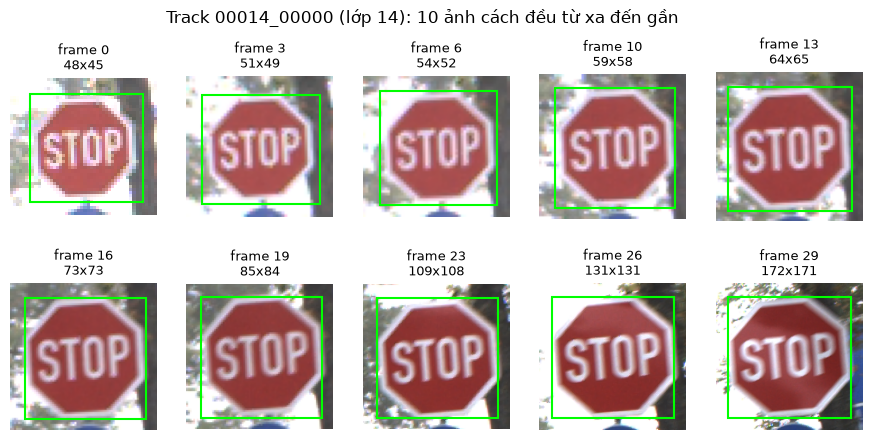

In [14]:
# Xem 10 frame trong cùng một lớp và cùng một track để so sánh

import matplotlib.patches as patches

# Chọn 1 lớp và 1 track trong lớp đó (đổi 2 số này để xem biển khác)
CLASS_ID = 14        # 14 = Stop
TRACK_IDX = 0        # track thứ mấy trong lớp (0 = track đầu tiên)

train["track_id"] = train["Path"].str.extract(r"(\d{5}_\d{5})_\d{5}")[0]
train["frame"] = train["Path"].str.extract(r"_(\d{5})\.png")[0].astype(int)

tracks_in_class = sorted(train.loc[train["ClassId"] == CLASS_ID, "track_id"].unique())
tid = tracks_in_class[TRACK_IDX]
t = train[train["track_id"] == tid].sort_values("frame").reset_index(drop=True)
print(f"Lớp {CLASS_ID} có {len(tracks_in_class)} track | track {tid} có {len(t)} ảnh")

# Lấy 10 ảnh cách đều nhau từ frame đầu đến frame cuối
n = 10
idx = np.linspace(0, len(t) - 1, n).round().astype(int)
sel = t.iloc[idx]

fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for ax, (_, r) in zip(axes.ravel(), sel.iterrows()):
    ax.imshow(Image.open(RAW / r["Path"]))
    ax.add_patch(patches.Rectangle(
        (r["Roi.X1"], r["Roi.Y1"]),
        r["Roi.X2"] - r["Roi.X1"], r["Roi.Y2"] - r["Roi.Y1"],
        fill=False, edgecolor="lime", linewidth=1.5))
    ax.set_title(f"frame {r['frame']}\n{r['Width']}x{r['Height']}", fontsize=9)
    ax.axis("off")
fig.suptitle(f"Track {tid} (lớp {CLASS_ID}): 10 ảnh cách đều từ xa đến gần")
plt.savefig(FIG / "one_track_10.png", dpi=200, bbox_inches="tight")
plt.show()